# 05 — Données synthétiques par copules

**Objectif :** générer des sites synthétiques avec une copule, puis évaluer s'ils aident à prédire Q10 dans des régions sans mesure.

**Pourquoi :** 131 sites, c'est peu pour généraliser à toute la planète. L'idée est d'estimer la loi jointe des variables explicatives et de Q10, puis de tirer de nouveaux sites dans cette loi pour entraîner les modèles sur davantage de données.

**Hypothèse à tester, et sa limite théorique :** un générateur ajusté sur nos sites ne contient aucune information de plus que ces sites. Les données synthétiques ne peuvent donc pas apporter de connaissance nouvelle sur Q10 ; au mieux, elles lissent ce que le modèle apprend (effet de régularisation). Seule l'expérience dira si cet effet aide.

**Démarche :**
- **Partie A — Méthode :** la copule gaussienne, construite pas à pas d'après Haugh (2016), *An Introduction to Copulas* (`context/An Introduction to Copulas.pdf`).
- **Partie B — Fidélité :** les sites synthétiques ressemblent-ils aux vrais ?
- **Partie C — Utilité :** aident-ils à prédire Q10 dans des régions jamais vues ? Protocole commun du projet (`src/protocole.py`), comme dans `04_comparaison_modeles.ipynb`.
- **Partie D — Sur-apprentissage :** limitent-ils le sur-apprentissage de nos modèles, en particulier dans les régions denses en mesures ?
- **Bilan :** est-ce un succès, et dans quelle mesure précise la méthode est-elle utile ?

**Données et variables :** la table de modélisation `data/dataset_v4.csv`. La copule décrit les 11 candidats numériques et la cible `log_Q10`, soit 12 variables. La typologie de végétation est laissée de côté, car elle est catégorielle et une copule décrit des variables continues. Les modèles de la partie C utilisent donc ces 11 candidats numériques.

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat** / **Décision**.

In [1]:
# Imports : numpy et pandas pour les données, matplotlib pour les graphiques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Chargement de la table de modélisation (cf. 02_selection_variables, partie B, étape 4)
v4 = pd.read_csv("../data/dataset_v4.csv")

In [3]:
# Les 11 candidats numériques (X) et les 12 variables décrites par la copule (X et la cible log_Q10)
num = ["lat", "lon", "MAT_public", "logMAP", "pH_public", "logN515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
cols = num + ["log_Q10"]

## Partie A — La copule gaussienne

### Étape 1 — Principe : séparer les marginales et la dépendance

**Objectif :** comprendre ce qu'est une copule, et pourquoi elle convient pour générer des données.

**Raisonnement :**

Le théorème de Sklar (Haugh, théorème 2) dit que toute loi jointe se décompose en deux parties. Pour un vecteur $X = (X_1, \dots, X_d)$ de fonction de répartition $F$ et de marginales $F_1, \dots, F_d$, il existe une copule $C$ telle que

$$F(x_1, \dots, x_d) = C\big(F_1(x_1), \dots, F_d(x_d)\big).$$

La copule $C$ est une fonction de répartition sur $[0, 1]^d$ dont les marginales sont uniformes : elle contient toute la dépendance entre les variables, et rien d'autre. On peut donc modéliser séparément :
- **chaque marginale** $F_j$ : la distribution de chaque variable prise seule ;
- **la copule** $C$ : la façon dont les variables varient ensemble.

**Propriété utile** (Haugh, proposition 3) : la copule ne change pas si l'on applique à une variable une transformation strictement croissante. Travailler avec `logMAP`, `logN515` et `log_Q10` plutôt qu'avec MAP, N515 et Q10 ne modifie donc pas la copule : le passage au log ne concerne que les marginales.

**Choix de la copule gaussienne** (Haugh, section 2.1) :

$$C_P^{\text{Gauss}}(u_1, \dots, u_d) = \Phi_P\big(\Phi^{-1}(u_1), \dots, \Phi^{-1}(u_d)\big),$$

où $\Phi$ est la fonction de répartition de la loi normale centrée réduite et $\Phi_P$ celle d'un vecteur gaussien centré de matrice de corrélation $P$. Elle est entièrement décrite par $P$, soit $d(d-1)/2 = 66$ corrélations pour nos $d = 12$ variables.
- C'est la copule la plus simple qui accepte 12 variables liées entre elles avec des signes et des intensités différents. Les copules archimédiennes (Gumbel, Clayton) imposent la même dépendance à toutes les paires (Haugh, section 2.3) : elles ne conviennent pas ici.
- **Limite connue :** elle n'a pas de dépendance de queue (Haugh, section 3.2). Les valeurs extrêmes de deux variables n'y ont pas tendance à survenir ensemble. Avec 131 sites, une telle dépendance ne serait de toute façon pas estimable de façon fiable.

### Étape 2 — Estimation : pseudo-observations et scores normaux

**Objectif :** estimer la matrice $P$ à partir de nos 131 sites.

**Raisonnement :** on suit la méthode semi-paramétrique de Haugh (section 4.2), en deux temps.

1. **Marginales :** on les estime par la fonction de répartition empirique, sans hypothèse sur leur forme. La valeur $x_{ij}$ (site $i$, variable $j$) devient une **pseudo-observation**

$$\hat u_{ij} = \hat F_j(x_{ij}) = \frac{\operatorname{rang}(x_{ij})}{n + 1}.$$

Diviser par $n + 1$ plutôt que par $n$ garde $\hat u_{ij}$ strictement entre 0 et 1, ce qui rend l'étape suivante possible ($\Phi^{-1}(1)$ est infini).

2. **Copule :** on calcule les **scores normaux** $z_{ij} = \Phi^{-1}(\hat u_{ij})$. Si la copule est gaussienne, chaque site $z_i = (z_{i1}, \dots, z_{id})$ suit la loi $\mathcal{N}(0, P)$. On estime donc $P$ par la matrice de corrélation des scores normaux, notée $\hat P$.

In [4]:
# Pseudo-observations : rang de chaque valeur dans sa colonne, divisé par n + 1
u = v4[cols].rank() / (len(v4) + 1)

In [5]:
# Import : loi normale centrée réduite (Phi et son inverse)
from scipy.stats import norm

In [6]:
# Scores normaux : z = Phi^-1(u)
z = pd.DataFrame(norm.ppf(u), columns=cols)

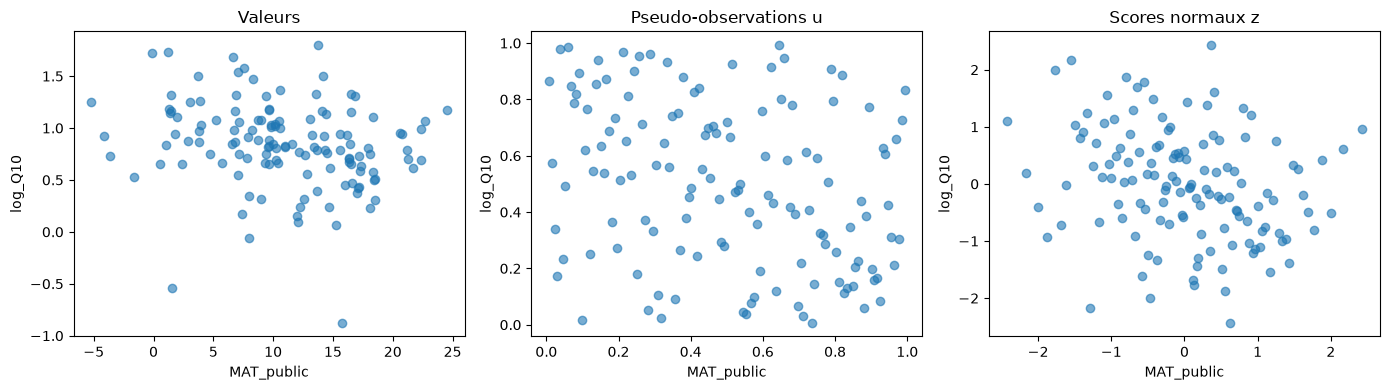

In [7]:
# Illustration sur la paire MAT – log(Q10) : le même nuage de points dans les trois espaces
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (table, titre) in zip(axes, [(v4, "Valeurs"), (u, "Pseudo-observations u"), (z, "Scores normaux z")]):
    ax.scatter(table.MAT_public, table.log_Q10, alpha=0.6)
    ax.set_title(titre); ax.set_xlabel("MAT_public"); ax.set_ylabel("log_Q10")
plt.tight_layout(); plt.show()

**Constat :**
- Le lien entre MAT et log(Q10), faible et négatif, est le même dans les trois espaces : les transformations sont croissantes, elles conservent l'ordre des sites.
- Les rangs effacent en revanche l'écart des valeurs extrêmes. Les deux sites isolés en bas du premier graphique (log Q10 < −0.5, soit Q10 < 0.6) deviennent simplement les deux plus petits rangs, au bord du nuage. La copule décrit cette dépendance par les rangs, et rien d'autre.

In [8]:
# Estimation de P : matrice de corrélation des scores normaux
P = z.corr()

In [9]:
# Plus petite valeur propre de P (doit être > 0 pour pouvoir simuler la loi N(0, P))
print(f"Plus petite valeur propre de P : {np.linalg.eigvalsh(P).min():.3f}")

Plus petite valeur propre de P : 0.108


In [10]:
# Ce que la copule « sait » de Q10 : corrélation du score normal de log_Q10 avec celui de chaque variable
P.log_Q10.drop("log_Q10").sort_values().round(2)

MAT_public     -0.26
pH_public      -0.09
clay           -0.07
logMAP         -0.04
CN             -0.02
SWC_mean        0.05
lat             0.07
sand            0.09
SWC_warm_rel    0.24
lon             0.26
logN515         0.31
Name: log_Q10, dtype: float64

**Constat :**
- La plus petite valeur propre de $\hat P$ vaut 0.11, donc $\hat P$ est une matrice de corrélation valide et l'on peut simuler la loi $\mathcal{N}(0, \hat P)$.
- Ce que la copule sait de Q10 se résume à des corrélations faibles, de −0.26 (MAT) à +0.31 (`logN515`), en passant par `lon` (+0.26) et `SWC_warm_rel` (+0.24). Les sites synthétiques hériteront de ces liens faibles, ni plus ni moins.

### Étape 3 — Contrôle : la copule gaussienne est-elle plausible pour nos données ?

**Objectif :** vérifier que la dépendance de nos variables est compatible avec une copule gaussienne.

**Raisonnement :** si la copule est gaussienne, le tau de Kendall de chaque paire de variables est entièrement fixé par la corrélation correspondante (Haugh, proposition 7) :

$$\tau_{jk} = \frac{2}{\pi} \arcsin\big(P_{jk}\big).$$

On compare donc, pour les 66 paires, le tau de Kendall mesuré sur nos sites à celui que prédit $\hat P$. Pour juger les écarts, on les compare à l'imprécision du tau de Kendall lui-même : avec $n$ sites et deux variables indépendantes, son écart-type vaut

$$\sigma_\tau = \sqrt{\frac{2(2n + 5)}{9n(n - 1)}}.$$

In [11]:
# Tau de Kendall mesuré, et tau prédit par la copule gaussienne estimée
tau_mesure = v4[cols].corr("kendall")
tau_predit = 2 / np.pi * np.arcsin(P)

In [12]:
# Les 66 paires distinctes (triangle supérieur des matrices)
paires = np.triu_indices(len(cols), 1)

In [13]:
# Écarts entre tau mesuré et tau prédit, comparés à l'écart-type d'échantillonnage du tau de Kendall
ecarts_tau = (tau_mesure.values - tau_predit.values)[paires]
n = len(v4)
print(f"Écart moyen (absolu) : {np.abs(ecarts_tau).mean():.3f} | écart maximal : {np.abs(ecarts_tau).max():.3f} | écart-type du tau : {np.sqrt(2 * (2 * n + 5) / (9 * n * (n - 1))):.3f}")

Écart moyen (absolu) : 0.030 | écart maximal : 0.092 | écart-type du tau : 0.059


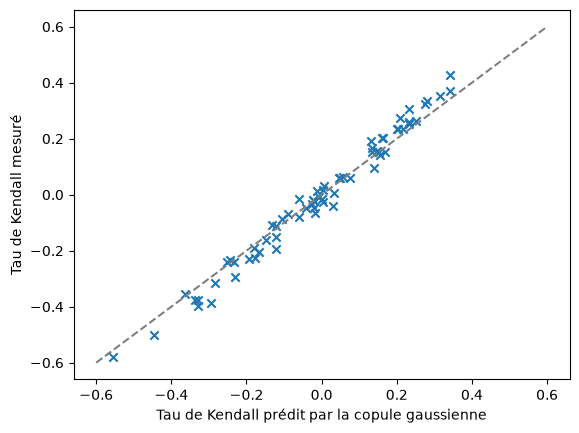

In [14]:
# Graphique : tau mesuré contre tau prédit, une croix par paire de variables
plt.scatter(tau_predit.values[paires], tau_mesure.values[paires], marker="x")
plt.plot([-0.6, 0.6], [-0.6, 0.6], c="grey", ls="--")
plt.xlabel("Tau de Kendall prédit par la copule gaussienne"); plt.ylabel("Tau de Kendall mesuré")
plt.show()

**Constat :**
- Les écarts sont faibles : 0.030 en moyenne et 0.092 au maximum, pour un écart-type d'échantillonnage du tau de 0.059. Aucune paire ne s'écarte nettement de ce que permet une copule gaussienne.
- Il y a toutefois une légère tendance systématique : pour les paires les plus liées, le tau mesuré est un peu plus fort, en valeur absolue, que le tau prédit. La copule estimée **atténue légèrement les dépendances les plus fortes**.

**Décision :** la copule gaussienne est une approximation raisonnable de la dépendance de nos 12 variables, paire par paire. On la retient.

### Étape 4 — Simulation de sites synthétiques

**Objectif :** tirer de nouveaux sites dans la loi estimée.

**Raisonnement :** on applique l'algorithme de simulation de Haugh (section 2.1), suivi de la transformation inverse de chaque marginale. On note d'un tilde les valeurs synthétiques.
1. Tirer $\tilde z \sim \mathcal{N}(0, \hat P)$ : un vecteur gaussien qui a les corrélations estimées.
2. Calculer $\tilde u_j = \Phi(\tilde z_j)$ pour chaque variable $j$ : le vecteur $\tilde u$ suit alors la copule gaussienne.
3. Calculer $\tilde x_j = \hat F_j^{-1}(\tilde u_j)$, c'est-à-dire le quantile empirique de la variable $j$ (interpolation linéaire entre les valeurs observées) : chaque variable retrouve sa distribution réelle.

**Conséquence de l'étape 3 :** chaque variable synthétique reste dans l'intervalle de ses valeurs observées. Les sites synthétiques **recombinent** des valeurs connues, sans explorer de climat ni de sol nouveaux.

In [15]:
# 1. Tirage de 1 000 vecteurs gaussiens de corrélation P (générateur aléatoire fixé pour la reproductibilité)
z_synth = np.random.default_rng(0).multivariate_normal(np.zeros(len(cols)), P, size=1000)

In [16]:
# 2. Passage dans [0, 1] : u = Phi(z)
u_synth = norm.cdf(z_synth)

In [17]:
# 3. Retour à l'échelle de chaque variable : quantile empirique de la variable au niveau u
synth = pd.DataFrame({c: np.quantile(v4[c], u_synth[:, j]) for j, c in enumerate(cols)})
synth.head()

,lat,lon,MAT_public,logMAP,pH_public,logN515,clay,sand,CN,SWC_mean,SWC_warm_rel,log_Q10
0,36.370451,111.763878,14.123191,7.465892,5.603727,7.991027,21.756239,30.417580,11.724343,0.289368,0.921454,0.733462
1,59.913689,25.103348,-4.059683,6.293045,6.210627,8.629904,10.555849,59.105256,12.855549,0.240553,0.851906,1.165016
2,30.983104,111.135737,10.288984,7.047041,6.245570,7.621296,31.201481,26.088889,10.593960,0.416571,0.999275,1.172642
3,36.075292,20.518334,14.400819,7.132822,4.773745,7.790704,16.112452,47.233275,10.591378,0.219535,0.851349,0.886788
4,29.622436,111.804576,21.184144,6.946636,7.320462,7.230787,33.498495,17.631992,9.630843,0.455579,0.950671,0.748474


**Décision :** on regroupe les étapes 2 et 4 dans une fonction. En partie C, la copule devra être ajustée sur les seuls sites d'entraînement de chaque pli de la validation croisée.

In [18]:
# Fonction : copule gaussienne ajustée sur un tableau de sites, puis tirage de n sites synthétiques
# (seed : graine, ou générateur aléatoire déjà créé)
def copule_gaussienne(sites, n, seed=0):
    P = pd.DataFrame(norm.ppf(sites.rank() / (len(sites) + 1))).corr()
    u = norm.cdf(np.random.default_rng(seed).multivariate_normal(np.zeros(len(P)), P, size=n))
    return pd.DataFrame({c: np.quantile(sites[c], u[:, j]) for j, c in enumerate(sites)})

## Partie B — Fidélité : les sites synthétiques ressemblent-ils aux vrais ?

### Étape 1 — Variables une à une, puis par paires

**Objectif :** vérifier que les 1 000 sites synthétiques de l'étape A4 reproduisent les distributions et les dépendances des vrais sites.

**Raisonnement :** les marginales sont reproduites par construction (quantiles empiriques) : on le vérifie sur quelques quantiles. Pour la dépendance, on compare le rho de Spearman (Haugh, section 3.1) de chacune des 66 paires dans les vrais sites et dans les sites synthétiques.

In [19]:
# Quantiles 5 %, 50 % et 95 % de chaque variable : vrais sites et sites synthétiques
pd.concat({"réels": v4[cols].quantile([0.05, 0.5, 0.95]).T, "synthétiques": synth.quantile([0.05, 0.5, 0.95]).T}, axis=1).round(2)

réels                 synthétiques                
                0.05    0.50    0.95         0.05    0.50    0.95
lat            22.92   36.52   55.40        22.78   36.52   55.49
lon          -107.52  101.58  137.42      -104.12  101.84  137.42
MAT_public      1.12   10.48   20.96         1.11   10.84   21.19
logMAP          6.35    7.00    7.65         6.35    6.99    7.68
pH_public       4.87    5.93    7.65         4.93    5.94    7.64
logN515         7.16    7.78    8.59         7.17    7.77    8.56
clay            9.51   24.32   33.15         9.47   24.81   33.32
sand           19.46   35.52   62.19        19.12   35.11   61.85
CN              8.53   12.54   22.45         8.50   12.29   21.76
SWC_mean        0.23    0.36    0.45         0.23    0.36    0.46
SWC_warm_rel    0.65    0.97    1.11         0.68    0.98    1.11
log_Q10         0.20    0.84    1.50         0.23    0.83    1.48

In [20]:
# Rho de Spearman des 66 paires : vrais sites et sites synthétiques
rho_reel = v4[cols].corr("spearman").values[paires]
rho_synth = synth.corr("spearman").values[paires]
print(f"Écart moyen (absolu) : {np.abs(rho_reel - rho_synth).mean():.3f} | écart maximal : {np.abs(rho_reel - rho_synth).max():.3f}")

Écart moyen (absolu) : 0.047 | écart maximal : 0.138


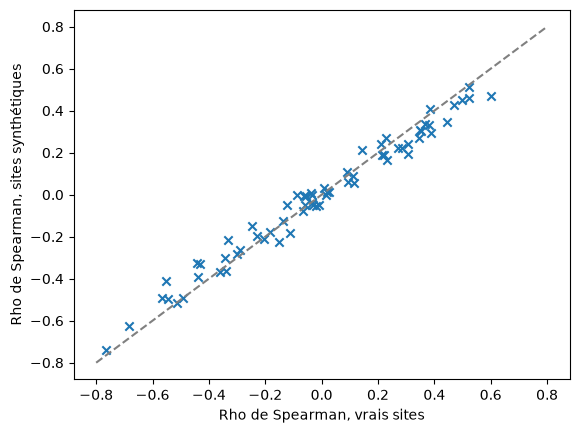

In [21]:
# Graphique : rho de Spearman synthétique contre réel, une croix par paire
plt.scatter(rho_reel, rho_synth, marker="x")
plt.plot([-0.8, 0.8], [-0.8, 0.8], c="grey", ls="--")
plt.xlabel("Rho de Spearman, vrais sites"); plt.ylabel("Rho de Spearman, sites synthétiques")
plt.show()

**Constat :**
- **Marginales :** les quantiles synthétiques coïncident avec les réels, à l'erreur de tirage près, comme prévu par construction.
- **Dépendance par paires :** les rho de Spearman synthétiques suivent les réels (écart moyen 0.047, maximal 0.138). On retrouve l'atténuation vue à l'étape A3 : pour les paires les plus liées, les croix sont un peu plus proches de 0 que la diagonale.

### Étape 2 — Test global : peut-on distinguer les vrais sites des faux ?

**Objectif :** juger la ressemblance sur les 12 variables à la fois.

**Raisonnement :**
- Un site synthétique peut être plausible variable par variable et paire par paire, tout en formant une combinaison irréaliste des 12 variables. On utilise donc un **test par classifieur** : on mélange 131 vrais sites et 131 sites synthétiques, et une forêt aléatoire apprend à les distinguer (validation croisée). Son AUC vaut 0.5 si elle n'y arrive pas mieux que le hasard, et 1 si elle les distingue parfaitement.
- **Point de comparaison :** la copule d'indépendance $\Pi(u_1, \dots, u_d) = \prod_{j=1}^{d} u_j$ (Haugh, section 1). Elle garde les vraies marginales mais ignore toute dépendance : on l'obtient en mélangeant chaque colonne indépendamment des autres.
- On répète le test sur 5 jeux synthétiques, car l'AUC varie d'un tirage à l'autre.

In [22]:
# Imports : forêt aléatoire de classification, validation croisée stratifiée répétée
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

In [23]:
# Fonction : AUC d'une forêt aléatoire qui distingue les vrais sites (0) des sites synthétiques (1), validation croisée 5 plis × 4
def auc_vrais_faux(faux):
    X = pd.concat([v4[cols], faux])
    y = np.r_[np.zeros(len(v4)), np.ones(len(faux))]
    return cross_val_score(RandomForestClassifier(random_state=0, n_jobs=-1), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=0), scoring="roc_auc").mean()

In [24]:
# Fonction : copule d'indépendance (chaque colonne mélangée indépendamment des autres)
independance = lambda seed: pd.DataFrame({c: np.random.default_rng(seed + j).permutation(v4[c].values) for j, c in enumerate(cols)})

In [25]:
# AUC sur 5 jeux de 131 sites synthétiques : copule d'indépendance, puis copule gaussienne
auc = pd.DataFrame({
    "indépendance": [auc_vrais_faux(independance(10 * s)) for s in range(5)],
    "gaussienne": [auc_vrais_faux(copule_gaussienne(v4[cols], len(v4), seed=s)) for s in range(5)],
})
auc.agg(["mean", "std"]).round(2)

,indépendance,gaussienne
mean,0.86,0.69
std,0.02,0.03


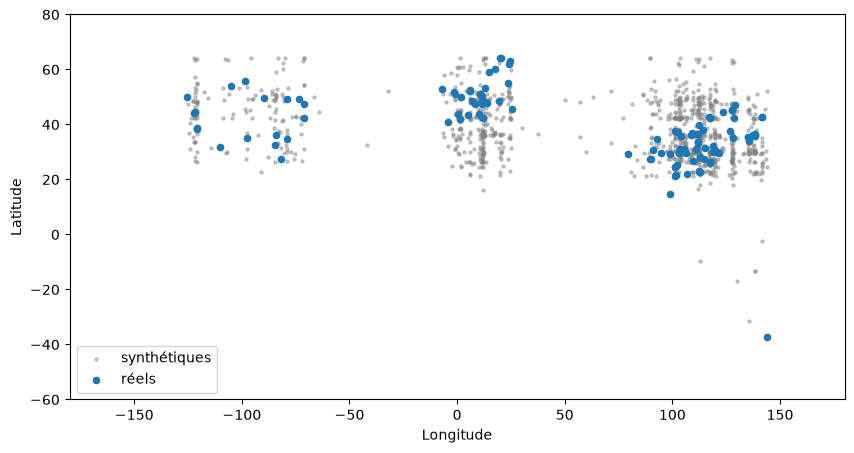

In [26]:
# Carte : vrais sites et 1 000 sites synthétiques (étape A4)
plt.figure(figsize=(10, 5))
plt.scatter(synth.lon, synth.lat, s=5, c="grey", alpha=0.4, label="synthétiques")
plt.scatter(v4.lon, v4.lat, s=20, label="réels")
plt.xlim(-180, 180); plt.ylim(-60, 80)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.legend()
plt.show()

**Constat :**
- La forêt distingue les sites de la copule gaussienne des vrais sites avec une AUC de 0.69 (± 0.03), contre 0.86 (± 0.02) pour la copule d'indépendance. La copule gaussienne capte donc une bonne part de la structure des données, mais pas toute : ses sites restent reconnaissables.
- La carte montre une raison de cet écart. Les sites synthétiques restent dans les trois bandes de longitude des vrais sites (Amérique du Nord, Europe, Asie de l'Est), mais chaque bande est remplie sur toute la plage de latitudes (≈ 20–65°N). En effet, une copule gaussienne ne décrit que des dépendances monotones : elle ne peut pas représenter le fait que chaque région a sa propre plage de latitudes. Elle place ainsi des sites à des endroits absents des données (Sahara, nord du Canada, Atlantique).
- Ces sites n'apportent pas pour autant de climats nouveaux : un site placé « au Sahara » a un climat et un sol recombinés à partir de nos sites (étape A4), pas ceux du Sahara.

**Bilan de la partie B :** la fidélité est bonne variable par variable et paire par paire, mais imparfaite sur l'ensemble des 12 variables, surtout pour la géographie.

## Partie C — Utilité : les sites synthétiques aident-ils à prédire Q10 ailleurs ?

### Étape 1 — Protocole

**Objectif :** mesurer si l'ajout de sites synthétiques améliore la prédiction de Q10 dans des régions jamais vues.

**Raisonnement :**
- **Protocole commun du projet** (`src/protocole.py`, cf. `INSTRUCTIONS.md`) : validation croisée spatiale par zones de 10° × 10°, 5 plis répétés 20 fois, mêmes découpages que dans les notebooks 02 et 04 ; cible log(Q10), erreurs mesurées sur l'échelle de Q10 (retour par exponentielle).
- **Métriques** (fonction `resumer`) : RMSE et MAE moyens sur les 100 plis ; R² calculé sur les prédictions hors-pli $\hat y_i$ de chaque répétition (chaque site est prédit une fois, quand sa zone est en test), puis moyenné sur les 20 répétitions ; gain de RMSE par rapport à la valeur fixe Q10 = 2.0 (`Q10_REFERENCE` de `src/protocole.py`, cf. `INSTRUCTIONS.md`).

$$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat y_i)^2}, \qquad R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat y_i)^2}{\sum_{i=1}^{n} (y_i - \bar y)^2}.$$

- **Comparaison de deux variantes** (fonction `comparer`) : écart de RMSE pli par pli, et son erreur standard corrigée de Nadeau et Bengio (2003). Une variante n'est jugée différente d'une autre que si l'écart dépasse une erreur standard.
- **Pas de fuite :** dans chaque pli, la copule est ajustée sur les seuls sites d'entraînement. Si elle voyait les sites de test, les sites synthétiques transporteraient leur information dans l'entraînement. Les sites synthétiques servent uniquement à l'entraînement ; l'évaluation porte toujours sur les vrais sites des zones de test.
- **Références** (identiques à `04_comparaison_modeles.ipynb`) : Q10 = 2.0 ; moyenne d'entraînement ; régression de Hacopian (MAT + MAP + pH) réentraînée sur chaque pli ; équation publiée de Hacopian.
- **Modèles :** le Ridge de `02_selection_variables.ipynb` (ici sur les 11 candidats numériques), et une forêt aléatoire. Modèle flexible et gourmand en données, la forêt est a priori celle qui a le plus à gagner de données supplémentaires.
- **Variantes d'entraînement :** vrais sites seuls ; vrais sites + 131 synthétiques (deux fois plus de lignes) ; vrais sites + 1 000 synthétiques ; 1 000 synthétiques seuls (« entraîné sur synthétique, testé sur réel »).

In [27]:
# Imports : fonctions communes du protocole (dossier src/), modèles et références
import sys
sys.path.append("..")
from src.protocole import decoupages_spatiaux, evaluer, resumer, comparer, Q10_REFERENCE
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [28]:
# Découpages de la validation croisée spatiale, identiques à ceux des notebooks 02 et 04
decoupages = decoupages_spatiaux(v4.bloc)

In [29]:
# Fonction : renvoie predire(tr, te) pour le protocole. Le modèle est entraîné sur log(Q10) avec les vrais sites du pli et n_synth sites
# synthétiques tirés d'une copule ajustée sur ces seuls vrais sites (garder_reels=False : synthétiques seuls). Retour à Q10 par exponentielle.
def predicteur(modele, n_synth=0, garder_reels=True):
    rng = np.random.default_rng(0)
    def predire(tr, te):
        reels = v4.iloc[tr][cols]
        synth_pli = copule_gaussienne(reels, n_synth, seed=rng)
        table = pd.concat([reels, synth_pli]) if garder_reels else synth_pli
        return np.exp(clone(modele).fit(table[num], table.log_Q10).predict(v4.iloc[te][num]))
    return predire

### Étape 2 — Résultats

**Objectif :** comparer les variantes d'entraînement entre elles et aux références, avec le protocole de l'étape 1.

**Raisonnement :** on évalue d'abord les références et les deux modèles entraînés sur les vrais sites seuls, puis les mêmes modèles avec des sites synthétiques. Toutes les variantes partagent les mêmes découpages : on peut donc les comparer pli par pli.

In [30]:
# Prédictions de l'équation publiée par Hacopian, pour tous les sites
hacopian_publie = 0.1093 - 0.0315 * v4.MAT_public + 0.0002 * v4.MAP_public + 0.4112 * v4.pH_public

In [31]:
# Variables du modèle de Hacopian (MAT, MAP brute en mm/an, pH)
H = v4[["MAT_public", "MAP_public", "pH_public"]]

In [32]:
# Modèles : Ridge identique à 02_selection_variables (pénalité choisie par validation interne), forêt aléatoire par défaut
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
foret = RandomForestRegressor(random_state=0, n_jobs=-1)

In [33]:
# Références et modèles entraînés sur les vrais sites seuls, sur les mêmes découpages spatiaux
resultats = {
    f"Q10 = {Q10_REFERENCE}": evaluer(lambda tr, te: np.full(len(te), Q10_REFERENCE), decoupages, v4.Q10),
    "moyenne": evaluer(lambda tr, te: np.full(len(te), v4.Q10.iloc[tr].mean()), decoupages, v4.Q10),
    "Hacopian réentraîné": evaluer(lambda tr, te: LinearRegression().fit(H.iloc[tr], v4.Q10.iloc[tr]).predict(H.iloc[te]), decoupages, v4.Q10),
    "Hacopian publié": evaluer(lambda tr, te: hacopian_publie.iloc[te], decoupages, v4.Q10),
    "Ridge, réels": evaluer(predicteur(ridge), decoupages, v4.Q10),
    "forêt, réels": evaluer(predicteur(foret), decoupages, v4.Q10),
}

In [34]:
# Variantes avec sites synthétiques : nombre de sites synthétiques, et vrais sites gardés ou non
variantes = {"réels + 131 synth.": (131, True), "réels + 1000 synth.": (1000, True), "1000 synth. seuls": (1000, False)}

In [35]:
# Ridge et forêt entraînés avec chaque variante
for nom, modele in [("Ridge", ridge), ("forêt", foret)]:
    for variante, (n_synth, garder_reels) in variantes.items():
        resultats[f"{nom}, {variante}"] = evaluer(predicteur(modele, n_synth, garder_reels), decoupages, v4.Q10)

In [36]:
# Tableau récapitulatif : RMSE, MAE, R² et gain par rapport à la valeur fixe Q10_REFERENCE
rmse_ref = resultats[f"Q10 = {Q10_REFERENCE}"][0].rmse.mean()
pd.DataFrame({k: resumer(s, o, v4.Q10, rmse_ref) for k, (s, o) in resultats.items()}).T.round(3)

,RMSE,MAE,R²,gain vs 2.2 (%)
Q10 = 2.2,1.007,0.733,-0.097,0.000
moyenne,0.980,0.748,-0.033,2.685
Hacopian réentraîné,0.963,0.717,-0.000,4.381
Hacopian publié,0.994,0.757,-0.057,1.303
"Ridge, réels",0.933,0.672,0.044,7.313
"forêt, réels",1.000,0.733,-0.084,0.698
"Ridge, réels + 131 synth.",0.954,0.687,0.009,5.242
"Ridge, réels + 1000 synth.",0.973,0.702,-0.030,3.361
"Ridge, 1000 synth. seuls",0.975,0.703,-0.033,3.144
"forêt, réels + 131 synth.",0.988,0.724,-0.057,1.882


In [37]:
# Écarts appariés de RMSE (erreur standard de Nadeau et Bengio) : chaque variante comparée au même modèle entraîné sur les vrais sites seuls
ecarts = pd.DataFrame({f"{nom}, {v}": comparer(resultats[f"{nom}, {v}"][0], resultats[f"{nom}, réels"][0]) for nom in ["Ridge", "forêt"] for v in variantes}).T
ecarts.round(3)

,écart,erreur standard,plis où a fait mieux (%)
"Ridge, réels + 131 synth.",0.021,0.023,29.0
"Ridge, réels + 1000 synth.",0.040,0.028,17.0
"Ridge, 1000 synth. seuls",0.042,0.030,18.0
"forêt, réels + 131 synth.",-0.012,0.030,65.0
"forêt, réels + 1000 synth.",-0.029,0.037,67.0
"forêt, 1000 synth. seuls",-0.024,0.044,64.0


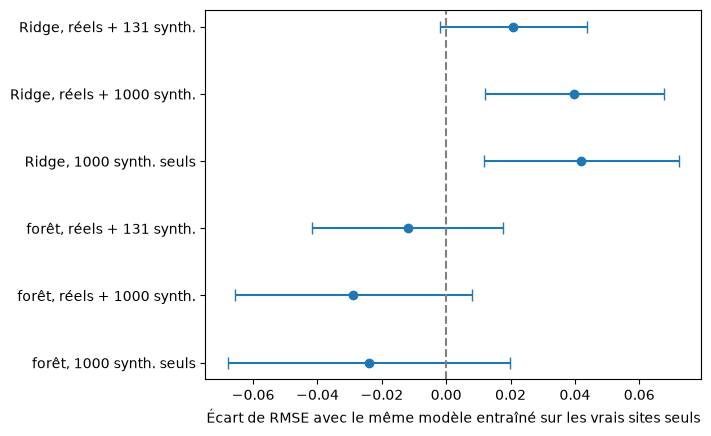

In [38]:
# Graphique : écart de RMSE ± une erreur standard (à gauche de 0 : les sites synthétiques aident)
plt.errorbar(ecarts["écart"], range(len(ecarts)), xerr=ecarts["erreur standard"], fmt="o", capsize=4)
plt.axvline(0, c="grey", ls="--")
plt.yticks(range(len(ecarts)), ecarts.index); plt.gca().invert_yaxis()
plt.xlabel("Écart de RMSE avec le même modèle entraîné sur les vrais sites seuls")
plt.show()

**Constat :**
- **Références :** mêmes valeurs que dans `04_comparaison_modeles.ipynb` (Q10 = 2.2 : 1.007 ; moyenne : 0.980 ; Hacopian réentraîné : 0.963 ; Hacopian publié : 0.994).
- **Modèles sur vrais sites :** le Ridge fait 0.933, soit 7.3 % d'erreur en moins que 2.2 (R² = 0.04). La forêt fait 1.000, à peine mieux que 2.2 et moins bien que la moyenne.
- **Ridge :** les sites synthétiques le **dégradent**. Avec 131 synthétiques : +0.021 ± 0.023, juste sous une erreur standard, moins bon dans 71 % des plis. Avec 1 000 : +0.040 ± 0.028, au-delà d'une erreur standard, moins bon dans 83 % des plis.
- **Forêt :** les sites synthétiques l'améliorent un peu (−0.012 avec 131, −0.029 avec 1 000), mais **sans dépasser une erreur standard** (0.030 et 0.037). Même au mieux (0.971), elle reste loin derrière le Ridge sur vrais sites (0.933).
- **Avec 1 000 synthétiques, les vrais sites ne comptent presque plus :** « réels + 1000 » et « 1000 seuls » donnent presque le même score, et le Ridge rejoint la forêt (0.971 à 0.976). Les deux modèles apprennent alors la relation décrite par la copule, qui prédit entre la moyenne (0.980) et Hacopian réentraîné (0.963).
- **Interprétation :** pour la forêt, qui sur-apprend seule, les sites synthétiques remplacent ce sur-apprentissage par la relation lisse de la copule : c'est une régularisation. Pour le Ridge, déjà régularisé, cette relation fait moins bien que ce qu'il apprend seul. L'étape 3 explique pourquoi.

### Étape 3 — Pourquoi les sites synthétiques dégradent-ils le Ridge ?

**Objectif :** expliquer le résultat de l'étape 2.

**Raisonnement :** le Ridge minimise

$$\sum_{i=1}^{n} \big(y_i - x_i^\top \beta\big)^2 + \alpha \lVert \beta \rVert^2.$$

Si l'on divise ce critère par $n$, on voit que la force réelle de la pénalité est $\alpha / n$ par site : à $\alpha$ égal, plus il y a de lignes, moins le modèle est régularisé. `RidgeCV` choisit $\alpha$ par validation interne. **Hypothèse :** les sites synthétiques trompent cette validation interne. Ils suivent exactement la relation que la copule a estimée, si bien que la validation interne conclut qu'on peut moins régulariser, alors que l'information disponible reste celle des vrais sites.

On vérifie en deux temps :
1. la pénalité par site $\alpha / n$ choisie par `RidgeCV`, avec et sans sites synthétiques ;
2. un contrôle à pénalité par site **identique** dans les deux cas.

In [39]:
# Pénalité choisie par RidgeCV sur les 131 vrais sites, puis sur ces sites + les 1 000 sites synthétiques de l'étape A4
for nom, table in {"réels": v4[cols], "réels + 1000 synth.": pd.concat([v4[cols], synth])}.items():
    alpha = clone(ridge).fit(table[num], table.log_Q10)[-1].alpha_
    print(f"{nom} : α = {alpha:.1f} | α / n = {alpha / len(table):.3f}")

réels : α = 62.1 | α / n = 0.474
réels + 1000 synth. : α = 41.8 | α / n = 0.037


In [40]:
# Pénalité par site choisie par RidgeCV sur les 131 vrais sites
alpha_par_site = clone(ridge).fit(v4[num], v4.log_Q10)[-1].alpha_ / len(v4)

In [41]:
# Contrôle : Ridge à pénalité par site fixée, pour ≈ 105 vrais sites d'entraînement par pli, avec ou sans 1 000 sites synthétiques
controle = {
    "Ridge α / n fixé, réels": evaluer(predicteur(make_pipeline(StandardScaler(), Ridge(alpha=alpha_par_site * 105))), decoupages, v4.Q10),
    "Ridge α / n fixé, réels + 1000 synth.": evaluer(predicteur(make_pipeline(StandardScaler(), Ridge(alpha=alpha_par_site * 1105)), n_synth=1000), decoupages, v4.Q10),
}
pd.DataFrame({k: resumer(s, o, v4.Q10, rmse_ref) for k, (s, o) in controle.items()}).T.round(3)

,RMSE,MAE,R²,gain vs 2.2 (%)
"Ridge α / n fixé, réels",0.928,0.668,0.055,7.860
"Ridge α / n fixé, réels + 1000 synth.",0.931,0.671,0.046,7.472


In [42]:
# Écart apparié du contrôle : effet des 1 000 sites synthétiques à pénalité par site égale
comparer(controle["Ridge α / n fixé, réels + 1000 synth."][0], controle["Ridge α / n fixé, réels"][0]).round(3)

écart                        0.004
erreur standard              0.012
plis où a fait mieux (%)    42.000
dtype: float64

**Constat :**
- **Pénalité :** sur les vrais sites, `RidgeCV` choisit $\alpha / n = 0.474$ ; avec les 1 000 sites synthétiques, $\alpha / n = 0.037$, soit une régularisation 13 fois plus faible. L'hypothèse est confirmée : trompée par les sites synthétiques, la validation interne relâche la régularisation.
- **Contrôle à pénalité par site égale :** les sites synthétiques **ne changent plus rien** (+0.004 ± 0.012, mieux dans 42 % des plis). La dégradation de l'étape 2 venait donc uniquement de la régularisation affaiblie. Les 1 000 sites synthétiques n'apportent aucune information au-delà des vrais sites.
- Attention : $\alpha$ a été choisi ici sur les 131 sites, sites de test compris. Les deux variantes en profitent de la même façon, donc la comparaison reste juste, mais ces scores ne sont pas des scores finaux.

## Partie D — Les sites synthétiques limitent-ils le sur-apprentissage ?

**Question :** supposons que le seul but des sites synthétiques soit d'empêcher nos modèles de sur-apprendre leurs sites d'entraînement, en particulier dans les régions denses en mesures (58 % des sites sont en Asie de l'Est, cf. `02_selection_variables.ipynb`). Ce but est-il atteint ?

On le teste en trois temps :
1. on mesure directement le sur-apprentissage ;
2. on regarde ce qui se passe dans les régions denses et dans les régions isolées ;
3. on compare aux moyens classiques de limiter le sur-apprentissage.

### Étape 1 — Mesure directe du sur-apprentissage

**Objectif :** vérifier si les sites synthétiques réduisent l'écart entre l'erreur sur les sites d'entraînement et l'erreur sur des régions jamais vues.

**Raisonnement :** un modèle sur-apprend quand il reproduit bien ses sites d'entraînement mais prédit mal de nouveaux sites. On mesure donc, pour chaque pli :
- l'erreur sur les **vrais** sites d'entraînement (les sites synthétiques sont exclus de cette mesure) ;
- l'erreur sur les sites de test (partie C).

L'écart entre les deux mesure le sur-apprentissage. Si les sites synthétiques remplissent leur rôle, cet écart doit diminuer.

In [43]:
# Découpages « entraînement » : sur chaque pli, on prédit les vrais sites d'entraînement eux-mêmes
decoupages_entrainement = [(s, tr, tr) for s, tr, _ in decoupages]

In [44]:
# Erreur d'entraînement, erreur de test et écart (sur-apprentissage), avec et sans 1 000 sites synthétiques
lignes = {}
for nom, modele in [("Ridge", ridge), ("forêt", foret)]:
    for variante, n_synth in [("réels", 0), ("réels + 1000 synth.", 1000)]:
        entrainement = evaluer(predicteur(modele, n_synth), decoupages_entrainement, v4.Q10)[0].rmse.mean()
        test = resultats[f"{nom}, {variante}"][0].rmse.mean()
        lignes[f"{nom}, {variante}"] = {"entraînement": entrainement, "test": test, "écart": test - entrainement}
pd.DataFrame(lignes).T.round(3)

,entraînement,test,écart
"Ridge, réels",0.902,0.933,0.031
"Ridge, réels + 1000 synth.",0.896,0.973,0.076
"forêt, réels",0.434,1.000,0.566
"forêt, réels + 1000 synth.",0.386,0.971,0.585


**Constat :**
- **Ridge :** avec 1 000 sites synthétiques, l'erreur d'entraînement baisse un peu (0.902 → 0.896) et l'erreur de test monte (0.933 → 0.973). Le sur-apprentissage est **multiplié par 2.5** (écart de 0.031 → 0.076). C'est la conséquence directe de la régularisation relâchée (partie C, étape 3).
- **Forêt :** elle sur-apprend fortement (0.434 en entraînement, 1.000 en test). Avec 1 000 sites synthétiques, l'écart **ne diminue pas** (0.566 → 0.585) : la forêt reproduit même un peu mieux ses vrais sites d'entraînement (0.386). Son erreur de test baisse (1.000 → 0.971), mais pas parce qu'elle colle moins à ses sites.
- **Interprétation :** les sites synthétiques sont tirés d'une copule ajustée sur ces mêmes sites d'entraînement. Ils en sont une version lissée, pas une contradiction : rien ne pousse le modèle à moins coller à ses sites.

**Conclusion de l'étape :** au sens strict (écart entre entraînement et test), les sites synthétiques ne réduisent le sur-apprentissage d'aucun des deux modèles.

### Étape 2 — Régions denses et régions isolées

**Objectif :** vérifier si les sites synthétiques corrigent le poids excessif des régions denses.

**Raisonnement :**
- **Composition :** pour corriger ce poids, les sites synthétiques devraient être plus nombreux dans les régions peu mesurées. On compare la part de l'Asie de l'Est parmi les vrais sites et parmi les sites synthétiques.
- **Erreur selon la densité :** pour chaque site, on compte ses voisins à moins de 1 000 km, l'échelle à laquelle des sites se ressemblent encore (semi-variogramme de 02). Les sites qui en ont au moins la médiane sont dits « denses », les autres « isolés ». On calcule ensuite l'erreur de chaque groupe sur les prédictions hors-pli de la partie C (une erreur par répétition, puis la moyenne). Si les sites synthétiques corrigent un sur-apprentissage des régions denses, c'est sur les sites isolés que l'erreur doit baisser.

In [45]:
# Part des sites en Asie de l'Est (lon 73–146°, lat 18–54°, comme dans 02) : vrais sites et sites synthétiques de l'étape A4
asie = lambda t: (t.lon.between(73, 146) & t.lat.between(18, 54)).mean()
print(f"Vrais sites : {asie(v4):.0%} | sites synthétiques : {asie(synth):.0%}")

Vrais sites : 58% | sites synthétiques : 56%


In [46]:
# Distances entre toutes les paires de sites (km, formule de haversine, comme dans 02)
lat, lon = np.radians(v4.lat.values), np.radians(v4.lon.values)
dist = 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat[:, None] - lat) / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat) * np.sin((lon[:, None] - lon) / 2) ** 2))

In [47]:
# Densité locale : nombre d'autres sites à moins de 1 000 km ; « denses » : au moins la médiane, « isolés » : moins
voisins = (dist < 1000).sum(axis=1) - 1
groupe = np.where(voisins >= np.median(voisins), "denses", "isolés")
print(f"Médiane : {np.median(voisins):.0f} voisins |", pd.Series(groupe).value_counts().to_dict())

Médiane : 15 voisins | {'denses': 66, 'isolés': 65}


In [48]:
# Fonction : RMSE de chaque groupe de sites, sur les prédictions hors-pli de chacune des 20 répétitions
def rmse_groupes(oof):
    return pd.DataFrame([{g: np.sqrt(np.mean((v4.Q10.values[groupe == g] - o[groupe == g]) ** 2)) for g in ["denses", "isolés"]} for o in oof])

In [49]:
# RMSE moyen par groupe, avec et sans 1 000 sites synthétiques
par_groupe = {k: rmse_groupes(resultats[k][1]) for k in ["Ridge, réels", "Ridge, réels + 1000 synth.", "forêt, réels", "forêt, réels + 1000 synth."]}
pd.DataFrame({k: v.mean() for k, v in par_groupe.items()}).T.round(3)

,denses,isolés
"Ridge, réels",0.808,1.106
"Ridge, réels + 1000 synth.",0.809,1.169
"forêt, réels",0.851,1.184
"forêt, réels + 1000 synth.",0.843,1.140


In [50]:
# Effet des 1 000 sites synthétiques dans chaque groupe : écart moyen de RMSE et part des répétitions où ils aident
for nom in ["Ridge", "forêt"]:
    for g in ["denses", "isolés"]:
        d = par_groupe[f"{nom}, réels + 1000 synth."][g] - par_groupe[f"{nom}, réels"][g]
        print(f"{nom}, sites {g} : écart {d.mean():+.3f} | mieux dans {(d < 0).mean():.0%} des répétitions")

Ridge, sites denses : écart +0.001 | mieux dans 55% des répétitions
Ridge, sites isolés : écart +0.062 | mieux dans 0% des répétitions
forêt, sites denses : écart -0.008 | mieux dans 60% des répétitions
forêt, sites isolés : écart -0.044 | mieux dans 80% des répétitions


**Constat :**
- **Composition :** 56 % des sites synthétiques sont en Asie de l'Est, contre 58 % des vrais sites. La copule reproduit le déséquilibre de l'échantillon, puisque ses marginales (dont `lat` et `lon`) sont celles des vrais sites. Elle ne donne pas plus de poids aux régions peu mesurées.
- **Erreur selon la densité :** tous les modèles se trompent bien plus sur les sites isolés (≈ 1.1 à 1.2) que sur les sites denses (≈ 0.8).
  - Sur les sites denses, les sites synthétiques ne changent presque rien (+0.001 pour le Ridge, −0.008 pour la forêt).
  - Sur les sites isolés, ils **dégradent** le Ridge (+0.062, moins bon dans toutes les répétitions) et **améliorent** la forêt (−0.044, mieux dans 80 % des répétitions).
- **Interprétation :** l'effet des sites synthétiques porte sur les sites éloignés de toute mesure, c'est-à-dire sur l'extrapolation, et non sur les régions denses. Avec 1 000 synthétiques, les deux modèles se rapprochent de la relation décrite par la copule (partie C, étape 2). Pour un site isolé, cette relation lisse vaut mieux que les prédictions en escalier de la forêt, mais moins bien que la relation régularisée du Ridge. Parmi ces quatre variantes, le Ridge sur vrais sites reste le meilleur sur les sites isolés (1.106).

### Étape 3 — Comparaison aux moyens classiques

**Objectif :** situer les sites synthétiques par rapport aux moyens classiques de limiter le sur-apprentissage, pour le seul modèle qu'ils améliorent, la forêt.

**Raisonnement :** une méthode n'est utile que si elle fait mieux, ou plus simplement, que les outils existants. On compare donc la forêt entraînée avec 1 000 sites synthétiques à trois alternatives, toutes évaluées sur les mêmes plis.
- **Feuilles plus grandes** (`min_samples_leaf` de 5 à 40, contre 1 par défaut) : chaque prédiction est alors une moyenne sur plus de sites, ce qui est la régularisation native de la forêt. Les quatre valeurs sont toutes montrées, sans en choisir une a posteriori.
- **La forêt du projet** (`src/modeles.py`, notebook 04) : ses hyperparamètres sont réglés par validation croisée spatiale interne.
- **Pondération par zone** : chaque zone de 10° reçoit le même poids total dans l'entraînement. C'est la réponse directe à la surreprésentation des régions denses ; on l'applique à la forêt et au Ridge.

In [51]:
# Import : forêt du projet (hyperparamètres réglés par validation croisée spatiale interne) et sa fonction d'ajustement
from src.modeles import random_forest, ajuster

In [52]:
# Fonction : prédiction de la forêt du projet, réglée sur les zones des seuls sites d'entraînement (11 candidats numériques)
def foret_projet(tr, te):
    modele = ajuster(random_forest(), v4.iloc[tr][num], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr])
    return np.exp(modele.predict(v4.iloc[te][num]))

In [53]:
# Fonction : renvoie predire(tr, te) pour un modèle entraîné avec des poids qui donnent le même poids total à chaque zone
# (cle_poids : nom du paramètre de poids, qui dépend du modèle)
def pondere_par_zone(modele, cle_poids="sample_weight"):
    def predire(tr, te):
        zones = v4.bloc.iloc[tr]
        poids = (1 / zones.map(zones.value_counts())).values
        return np.exp(clone(modele).fit(v4.iloc[tr][num], v4.log_Q10.iloc[tr], **{cle_poids: poids}).predict(v4.iloc[te][num]))
    return predire

In [54]:
# Forêts régularisées par des feuilles plus grandes
regularisations = {f"forêt, min_samples_leaf = {k}": evaluer(predicteur(RandomForestRegressor(min_samples_leaf=k, random_state=0, n_jobs=-1)), decoupages, v4.Q10) for k in [5, 10, 20, 40]}

In [55]:
# Forêt du projet, forêt pondérée par zone, et forêt avec 1 000 sites synthétiques (partie C)
regularisations["forêt du projet (réglée)"] = evaluer(foret_projet, decoupages, v4.Q10)
regularisations["forêt pondérée par zone"] = evaluer(pondere_par_zone(foret), decoupages, v4.Q10)
regularisations["forêt, réels + 1000 synth. (copule)"] = resultats["forêt, réels + 1000 synth."]

In [56]:
# Tableau : RMSE de chaque façon de régulariser la forêt, et écart apparié avec la forêt par défaut entraînée sur les vrais sites
pd.DataFrame({k: {"RMSE": s.rmse.mean(), **comparer(s, resultats["forêt, réels"][0])} for k, (s, _) in regularisations.items()}).T.round(3)

,RMSE,écart,erreur standard,plis où a fait mieux (%)
"forêt, min_samples_leaf = 5",0.986,-0.014,0.029,63.0
"forêt, min_samples_leaf = 10",0.982,-0.018,0.037,52.0
"forêt, min_samples_leaf = 20",0.962,-0.038,0.041,69.0
"forêt, min_samples_leaf = 40",0.990,-0.010,0.049,49.0
forêt du projet (réglée),0.980,-0.020,0.027,67.0
forêt pondérée par zone,1.003,0.004,0.034,48.0
"forêt, réels + 1000 synth. (copule)",0.971,-0.029,0.037,67.0


In [57]:
# Ridge pondéré par zone (le poids passe par l'étape RidgeCV de la chaîne)
ridge_pondere = evaluer(pondere_par_zone(ridge, "ridgecv__sample_weight"), decoupages, v4.Q10)

In [58]:
# Comparaisons directes : forêt du projet contre forêt + copule ; Ridge pondéré contre Ridge sur vrais sites
pd.DataFrame({
    "forêt du projet − forêt + 1000 synth.": comparer(regularisations["forêt du projet (réglée)"][0], resultats["forêt, réels + 1000 synth."][0]),
    "Ridge pondéré par zone − Ridge, réels": comparer(ridge_pondere[0], resultats["Ridge, réels"][0]),
}).T.round(3)

,écart,erreur standard,plis où a fait mieux (%)
forêt du projet − forêt + 1000 synth.,0.009,0.031,38.0
"Ridge pondéré par zone − Ridge, réels",0.021,0.020,26.0


**Constat :**
- **Toutes les façons de régulariser la forêt se valent :** leurs scores vont de 0.962 à 0.990, et aucune ne bat la forêt par défaut de plus d'une erreur standard. Les sites synthétiques (0.971) sont dans ce lot, ni meilleurs ni pires que des feuilles plus grandes ou que la forêt réglée du projet (écart de +0.009 ± 0.031 entre les deux).
- **Même bien régularisée, la forêt reste loin du Ridge** sur vrais sites (0.933), et tout juste au niveau de la régression de Hacopian réentraînée (0.963).
- **La pondération par zone n'aide pas non plus :** elle est sans effet sur la forêt (+0.004) et dégrade le Ridge (+0.021 ± 0.020, au-delà d'une erreur standard). Donner moins de poids aux régions denses fait perdre de l'information, sans en apporter aux régions isolées.

**Conclusion de l'étape :** pour la forêt, les sites synthétiques sont une régularisation parmi d'autres, ni meilleure ni pire. Ils sont en revanche plus coûteux (10 fois plus de lignes, une copule à ajuster dans chaque pli) et plus risqués (partie C, étape 3).

## Bilan — Les sites synthétiques sont-ils un succès contre le sur-apprentissage ?

**Réponse courte : non.** Jugée sur ce seul objectif (empêcher nos modèles de sur-apprendre leurs sites d'entraînement, en particulier dans les régions denses), l'augmentation par copule échoue, pour trois raisons mesurées.
1. **Elle ne réduit pas le sur-apprentissage** (étape D1). L'écart entre erreur de test et erreur d'entraînement passe de 0.031 à 0.076 pour le Ridge, et reste à ≈ 0.57–0.59 pour la forêt.
2. **Elle ne corrige pas le poids des régions denses** (étape D2). Les sites synthétiques reproduisent le déséquilibre (56 % en Asie de l'Est, contre 58 % pour les vrais sites) et ne changent rien à l'erreur sur les sites denses.
3. **Là où elle aide, elle ne fait pas mieux qu'une régularisation classique** (étape D3). La forêt passe de 1.000 à 0.971, comme avec des feuilles plus grandes ou avec la forêt réglée du projet, et aucune de ces forêts n'approche le Ridge (0.933).

**Ce que fait réellement la méthode.** Entraîner un modèle sur des sites synthétiques revient à le tirer vers la relation décrite par la copule : une relation linéaire entre scores normaux, estimée sans pénalité sur nos sites. Plus il y a de sites synthétiques, plus le modèle s'en rapproche (≈ 0.97 avec 1 000, quel que soit le modèle). Tout le reste en découle :
- un modèle qui, seul, fait moins bien que cette relation s'améliore (la forêt par défaut, 1.000) ; un modèle qui fait mieux se dégrade (le Ridge, 0.933) ;
- l'effet porte sur les sites isolés, là où le modèle extrapole, et non sur les régions denses ;
- la copule est elle-même un modèle ajusté sur nos 131 sites. Elle hérite de leurs biais (poids des régions denses) et de leur bruit, et les sites synthétiques transmettent ces défauts sous l'apparence de 1 000 observations. C'est ce qui trompe la validation interne du Ridge (partie C, étape 3).

### Dans quelle mesure la méthode est-elle utile ?

| Situation | Utile ? | Pourquoi (chiffres de ce notebook) |
|---|---|---|
| Modèle flexible peu régularisé (forêt par défaut) | **un peu** | lissage vers la relation de la copule : −0.029, sous une erreur standard ; autant qu'une régularisation classique, pas plus |
| Modèle déjà régularisé (Ridge ; même mécanisme attendu, non testé, pour l'Elastic Net et le GAM pénalisé) | **non, nuisible** | +0.040 avec 1 000 synthétiques ; la validation interne divise la pénalité par site par 13 ; à pénalité égale, effet nul |
| Modèle dont les hyperparamètres sont réglés par validation interne (les 8 modèles de 04) | **risqué** | les sites synthétiques entreraient dans la validation interne et la tromperaient, comme pour `RidgeCV` |
| Correction du poids des régions denses | **non** | les sites synthétiques reproduisent le déséquilibre (56 % contre 58 % en Asie de l'Est) |
| Prédiction dans des régions et des climats sans mesure (carte mondiale) | **non** | aucune valeur hors des intervalles observés ; emplacements irréalistes (partie B) |
| Études de simulation (relation connue, test de nos méthodes) | **oui** | c'est là qu'un générateur réaliste est vraiment utile |

**Si l'on voulait malgré tout l'utiliser**, quatre conditions seraient indispensables :
1. ajuster la copule sur les seuls sites d'entraînement de chaque pli (sinon, fuite d'information) ;
2. traiter le nombre de sites synthétiques comme un hyperparamètre, choisi sur de vrais sites ;
3. ne jamais laisser de sites synthétiques dans une validation interne ;
4. comparer à la régularisation native du modèle, qui fait ici aussi bien, plus simplement.

### Le vrai problème des régions peu mesurées

Tous les modèles se trompent bien plus sur les sites isolés (≈ 1.1 à 1.2) que sur les sites denses (≈ 0.8). Ni les sites synthétiques ni la pondération par zone ne réduisent nettement cet écart. Le problème des régions peu mesurées n'est donc pas un sur-apprentissage des régions denses, mais un **manque d'information**. Nos variables n'expliquent pas la structure spatiale de Q10 (semi-variogramme des résidus, `02_selection_variables.ipynb`, partie C), et aucune transformation de nos 131 sites ne peut créer cette information. Seules de nouvelles mesures, ou des connaissances extérieures (autres bases de données, modèles de processus), peuvent la réduire.

**Décision proposée (à valider) :**
- ne pas utiliser l'augmentation par copule dans la suite du projet ;
- pour limiter le sur-apprentissage des modèles de `04_comparaison_modeles.ipynb`, s'appuyer sur leur régularisation native, réglée par validation croisée spatiale interne, comme c'est déjà prévu.

**Autres méthodes de génération :** aucune raison forte de penser qu'elles feraient mieux, car la limite est l'information contenue dans 131 sites, pas la fidélité du générateur.
- Une copule plus flexible (copule en vigne, copule de Student) améliorerait la fidélité, pas l'information.
- Les générateurs à réseaux de neurones (GAN, auto-encodeurs variationnels) demandent des milliers d'exemples : avec 131 sites, ils recopieraient ou déformeraient les données.
- Ajouter du bruit aux sites existants équivaut, pour un modèle linéaire, à une pénalité Ridge (Bishop, 1995), que l'on a déjà.

**Usage des copules qui reste pertinent : un laboratoire de simulation.** On peut générer des jeux de données réalistes dans lesquels la vraie relation avec Q10 est connue, pour mesurer si nos méthodes (LASSO, validation croisée spatiale) savent la retrouver. Cela rendrait reproductible la simulation de puissance évoquée dans `AgentDiscussion/02_selection_variables.md`.